In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
path = "/content/drive/MyDrive/AIML_Learning/Mini_Project1_TMDB_Analysis/cleaned_files/"

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cast = pd.read_csv(path + "cast_cleaned.csv")
crew = pd.read_csv(path + "crew_cleaned.csv")
genres = pd.read_csv(path + "genres_cleaned.csv")
movie_genres = pd.read_csv(path + "movie_genres_cleaned.csv")
movie_keywords = pd.read_csv(path + "movie_keywords_cleaned.csv")
movies = pd.read_csv(path + "movies_cleaned.csv")

##Univariate Analysis

###Distribution of Movie Budgets

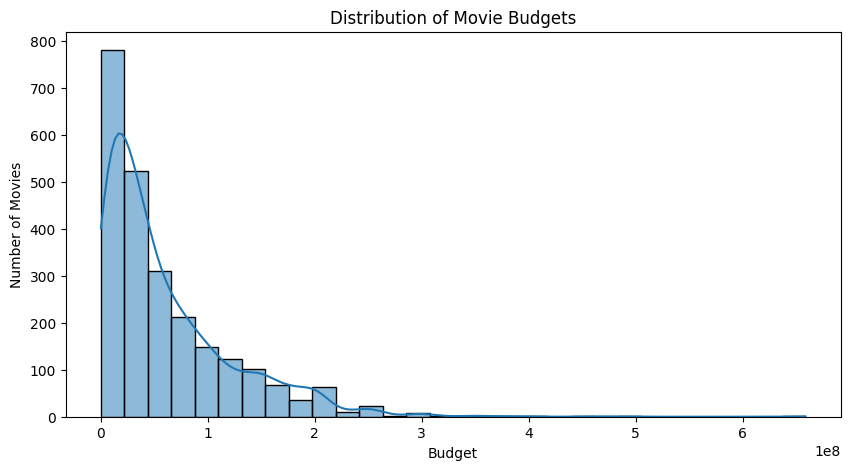

In [7]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=movies[movies['budget'] > 0],
    x='budget',
    bins=30,
    kde=True
)

plt.title('Distribution of Movie Budgets')
plt.xlabel('Budget')
plt.ylabel('Number of Movies')

plt.show()

####Insight
Most movies were produced with relatively lower budgets, while only a small number of movies had very high production budgets

###Distribution of Movie Runtimes

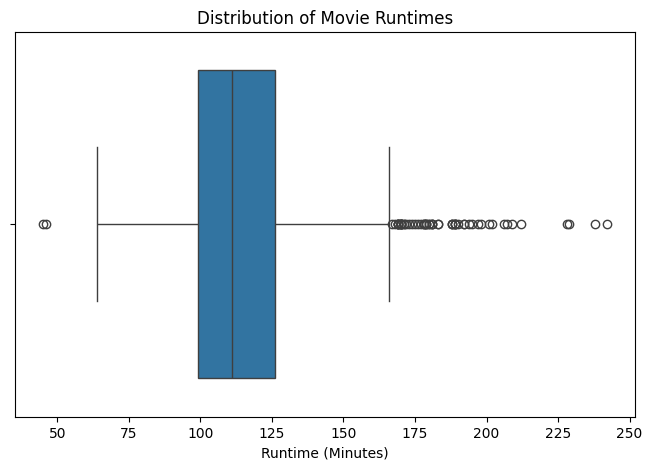

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=movies, x='runtime')

plt.title('Distribution of Movie Runtimes')
plt.xlabel('Runtime (Minutes)')

plt.show()

####Insight
Most movies have runtimes within a relatively consistent range, while a few movies have unusually short or long durations.

###Distribution of Vote Average

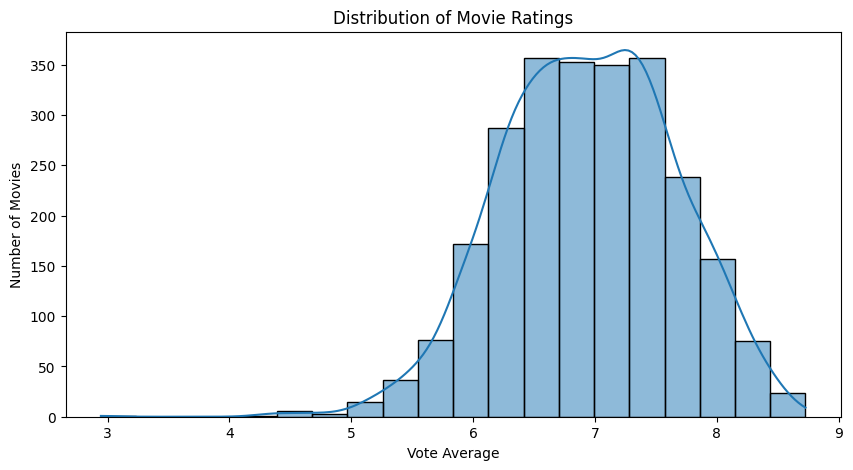

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=movies,
    x='vote_average',
    bins=20,
    kde=True
)

plt.title('Distribution of Movie Ratings')
plt.xlabel('Vote Average')
plt.ylabel('Number of Movies')

plt.show()

####Insight
Most movies received ratings within the middle score range, indicating that extremely high and extremely low ratings are less common.

###Number of Movies per Genre

In [13]:
movie_genres = movie_genres.merge(
    genres,
    on='genre_id',
    how='left'
)

In [14]:
genre_counts = movie_genres['genre_name'].value_counts()

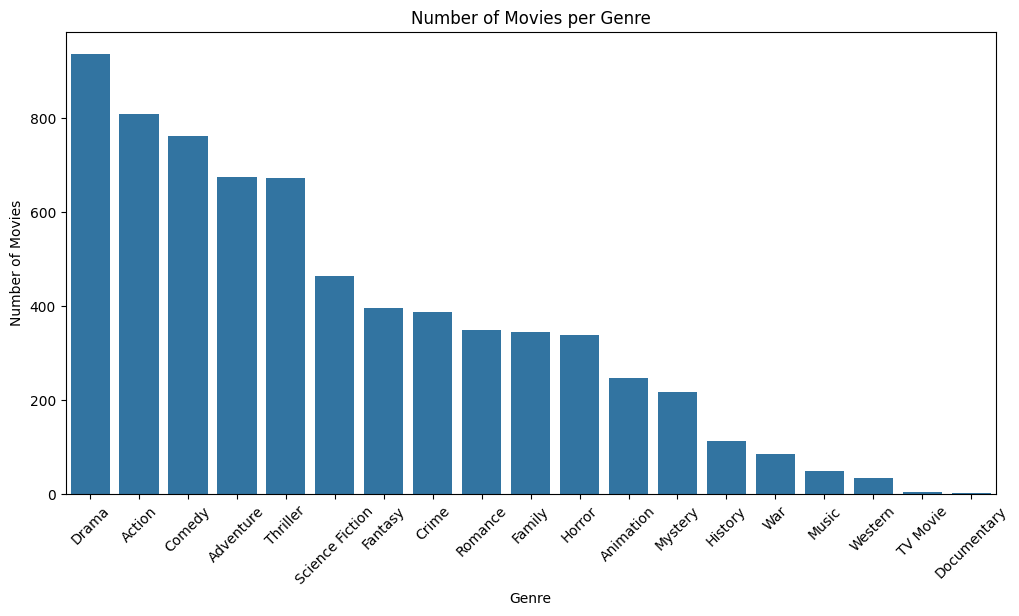

In [15]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.index,
    y=genre_counts.values
)

plt.xticks(rotation=45)
plt.title('Number of Movies per Genre')
plt.xlabel('Genre')
plt.ylabel('Number of Movies')

plt.show()

####Insight
The genre distribution helps identify the most frequently produced movie categories. It also highlights genres with comparatively lower representation.

##Bivariate Analysis

###Budget vs Revenue

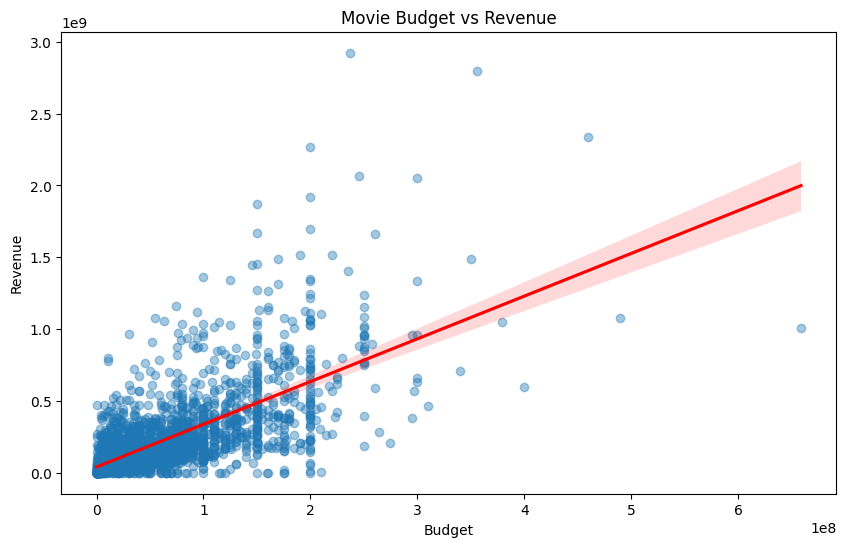

In [16]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=movies,
    x='budget',
    y='revenue',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.title('Movie Budget vs Revenue')
plt.xlabel('Budget')
plt.ylabel('Revenue')

plt.show()

####Insight
Higher-budget movies generally tend to generate higher revenues, although some low-budget movies also achieve significant commercial success

###Popularity vs Vote Count

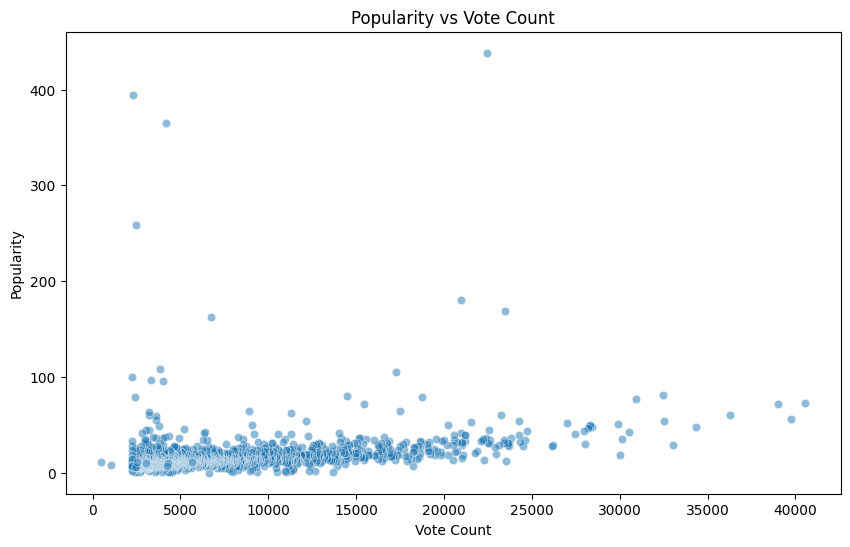

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=movies,
    x='vote_count',
    y='popularity',
    alpha=0.5
)

plt.title('Popularity vs Vote Count')
plt.xlabel('Vote Count')
plt.ylabel('Popularity')

plt.show()

####Insight
Vote count and popularity do not always follow the same pattern. Some movies achieve high popularity despite receiving relatively fewer votes.

###Average Rating by Genre

In [20]:
movie_rating = movies.merge(
    movie_genres,
    left_on='movie_id',
    right_on='movie_id',
    how='left'
)

movie_rating = movie_rating.merge(
    genres,
    on='genre_id',
    how='left'
)

In [22]:
print(movie_rating.columns.tolist())

['movie_id', 'title', 'original_language', 'release_date', 'runtime', 'budget', 'revenue', 'popularity', 'vote_average', 'vote_count', 'status', 'overview', 'genre_id', 'genre_name_x', 'genre_name_y']


In [23]:
movie_rating[['genre_name_x', 'genre_name_y']].head(10)

,genre_name_x,genre_name_y
0,Adventure,Adventure
1,Drama,Drama
2,Science Fiction,Science Fiction
3,Action,Action
4,Science Fiction,Science Fiction
5,Adventure,Adventure
6,Science Fiction,Science Fiction
7,Action,Action
8,Adventure,Adventure
9,Action,Action


In [24]:
genre_rating = movie_rating.groupby(
    'genre_name_x'
)['vote_average'].mean().sort_values(ascending=False)

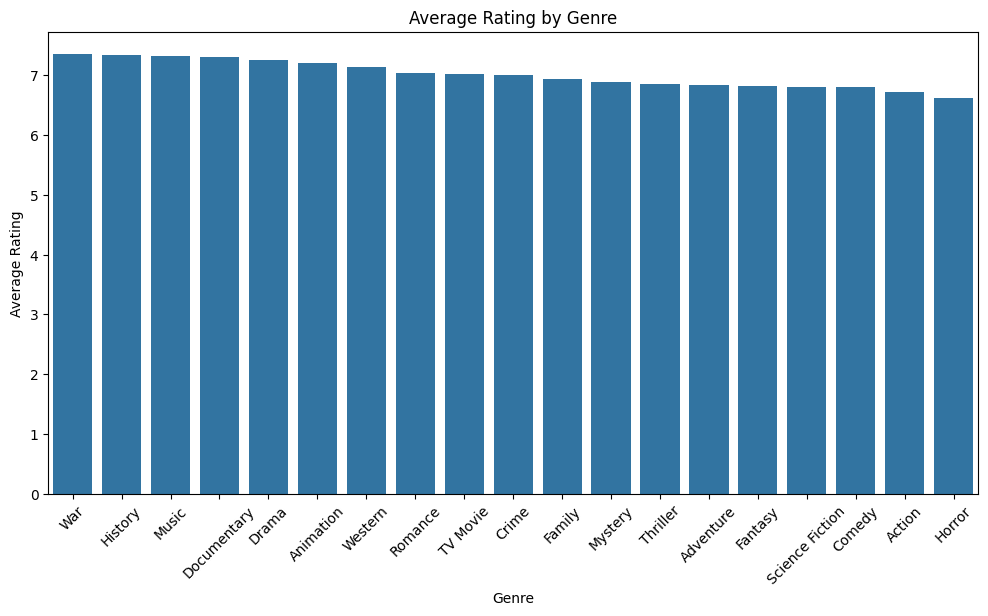

In [25]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_rating.index,
    y=genre_rating.values
)

plt.xticks(rotation=45)
plt.title('Average Rating by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Rating')

plt.show()

####Insight
Certain genres receive higher average audience ratings than others, indicating differences in audience reception across movie categories.

###Number of Movies Released per Year

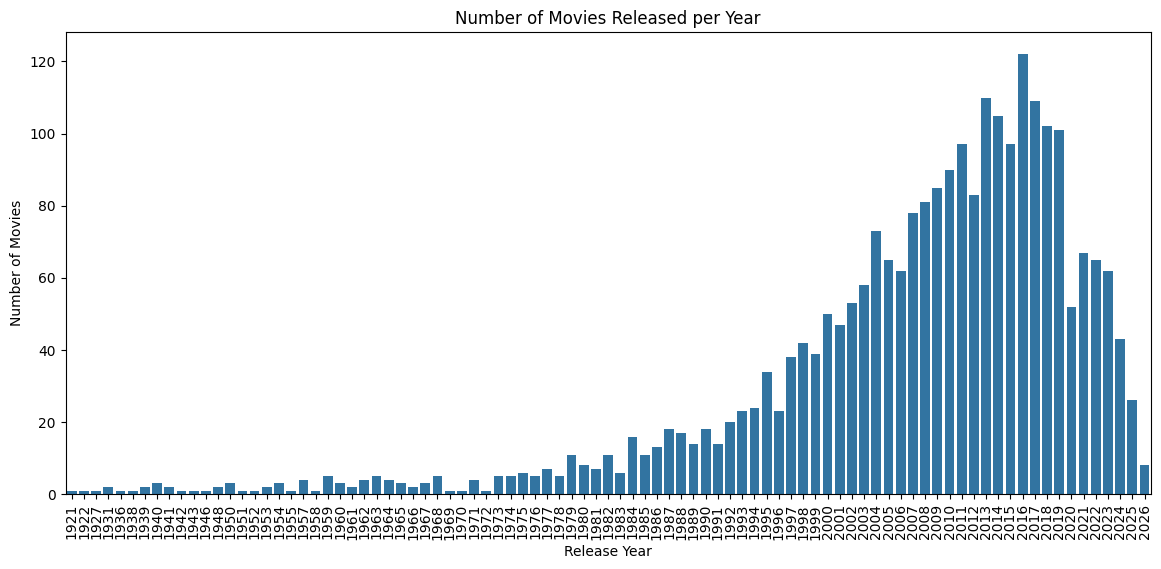

In [26]:
movies['release_year'] = pd.to_datetime(
    movies['release_date']
).dt.year

year_counts = movies['release_year'].value_counts().sort_index()

plt.figure(figsize=(14, 6))

sns.barplot(
    x=year_counts.index,
    y=year_counts.values
)

plt.xticks(rotation=90)
plt.title('Number of Movies Released per Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Movies')

plt.show()

####Insight
The yearly movie release trend highlights changes in film production over time, with certain years showing significantly higher movie output.
*   Highest movie output year: 2016
*   Number of movies: 122

##Multivariate Analysis

###Correlation Heatmap

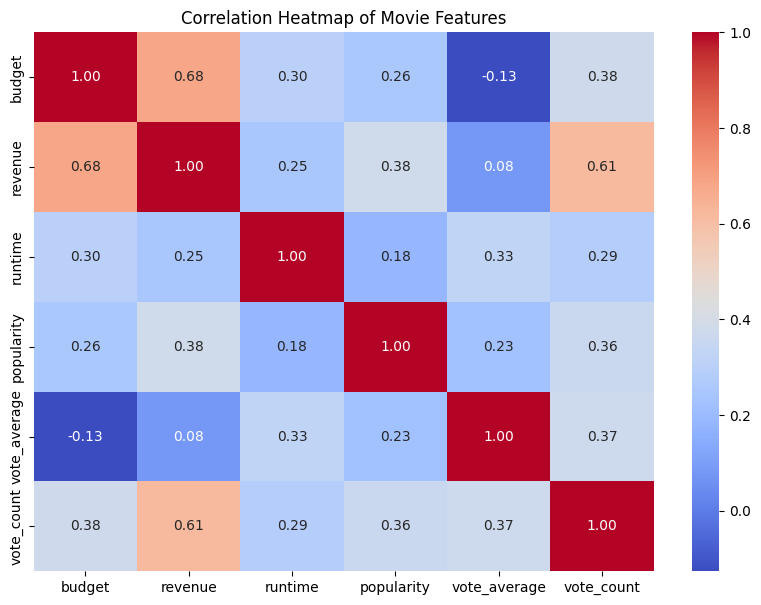

In [27]:
corr_data = movies[
    [
        'budget',
        'revenue',
        'runtime',
        'popularity',
        'vote_average',
        'vote_count'
    ]
]

correlation = corr_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Movie Features')

plt.show()

####Insight
 Revenue shows a positive relationship with budget, while vote count and popularity can also show meaningful relationships. However, correlation does not necessarily imply causation.

###Pairplot by Primary Genre

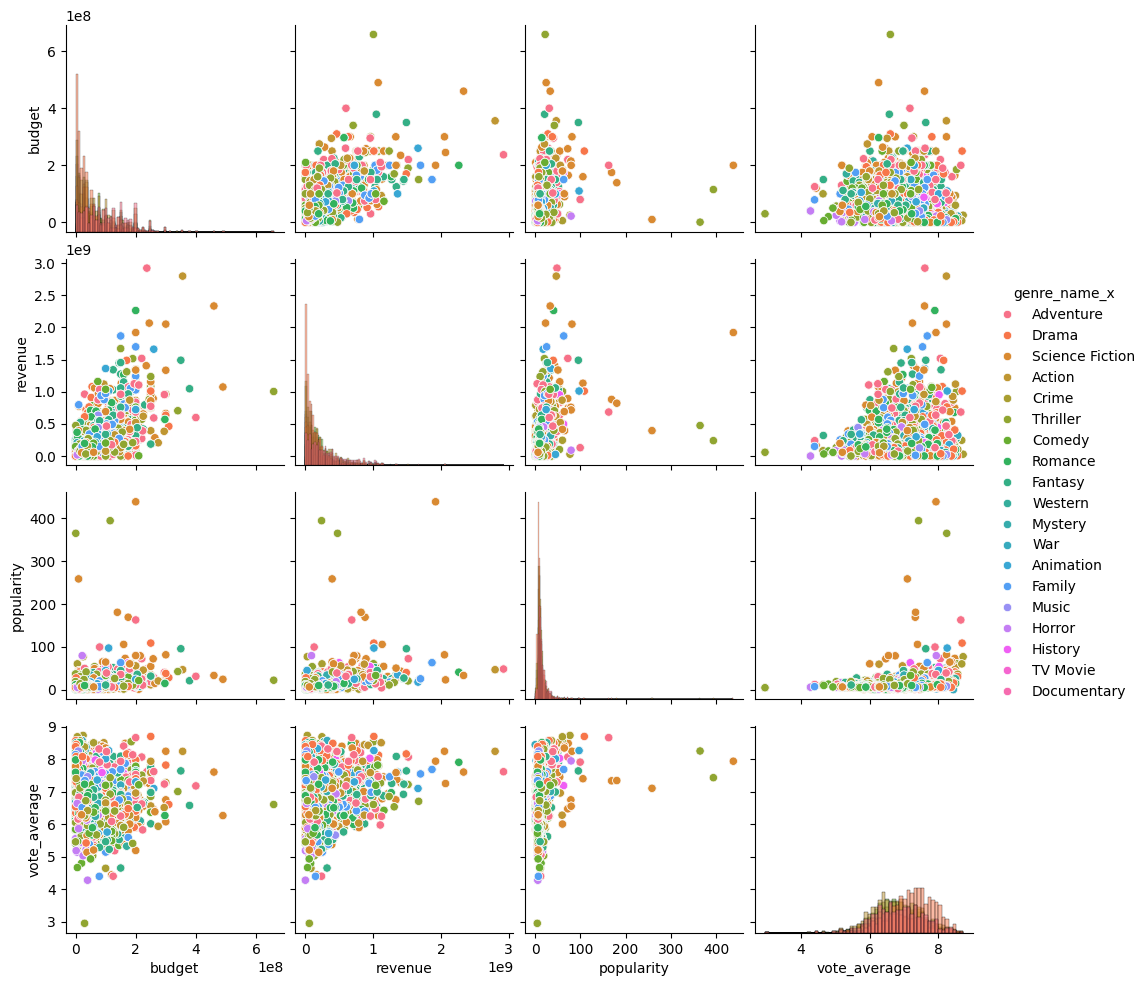

In [29]:
pair_data = movie_rating[
    [
        'budget',
        'revenue',
        'popularity',
        'vote_average',
        'genre_name_x'
    ]
].dropna()

sns.pairplot(
    pair_data,
    hue='genre_name_x',
    diag_kind='hist'
)

plt.show()

####Insight
The pairplot provides an overall comparison of financial performance, popularity and audience ratings across different genres. It helps identify patterns and differences between movie categories.

###Budget vs Revenue by Genre

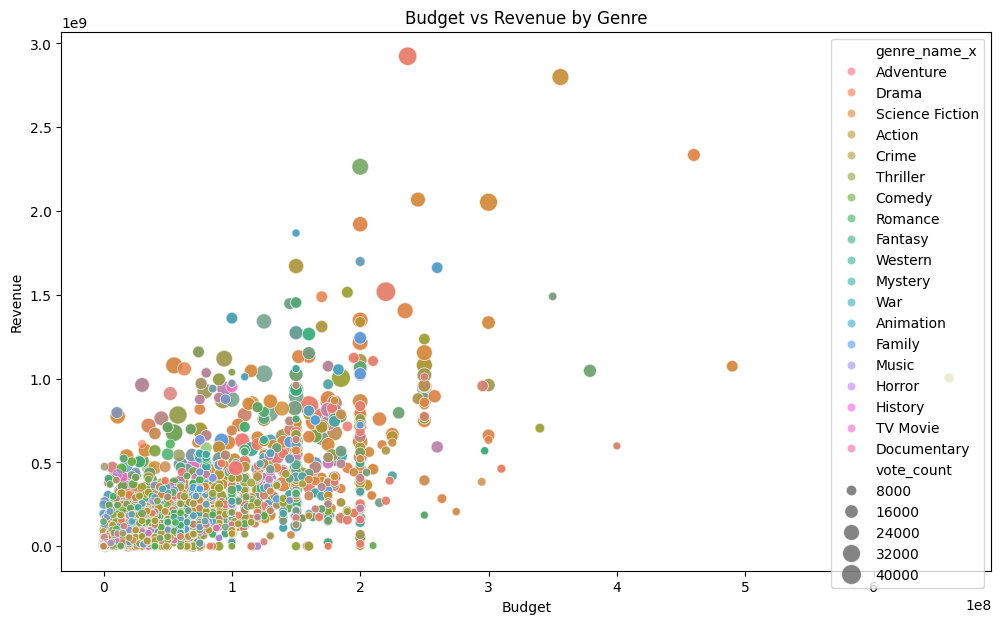

In [33]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=movie_rating,
    x='budget',
    y='revenue',
    hue='genre_name_x',
    size='vote_count',
    sizes=(20, 200),
    alpha=0.6
)

plt.title('Budget vs Revenue by Genre')
plt.xlabel('Budget')
plt.ylabel('Revenue')

plt.show()

####Insight
The chart compares financial performance across genres. Larger circles represent movies with higher vote counts, helping identify movies that combine strong audience engagement with high revenue.

###Vote Average Distribution by Genre

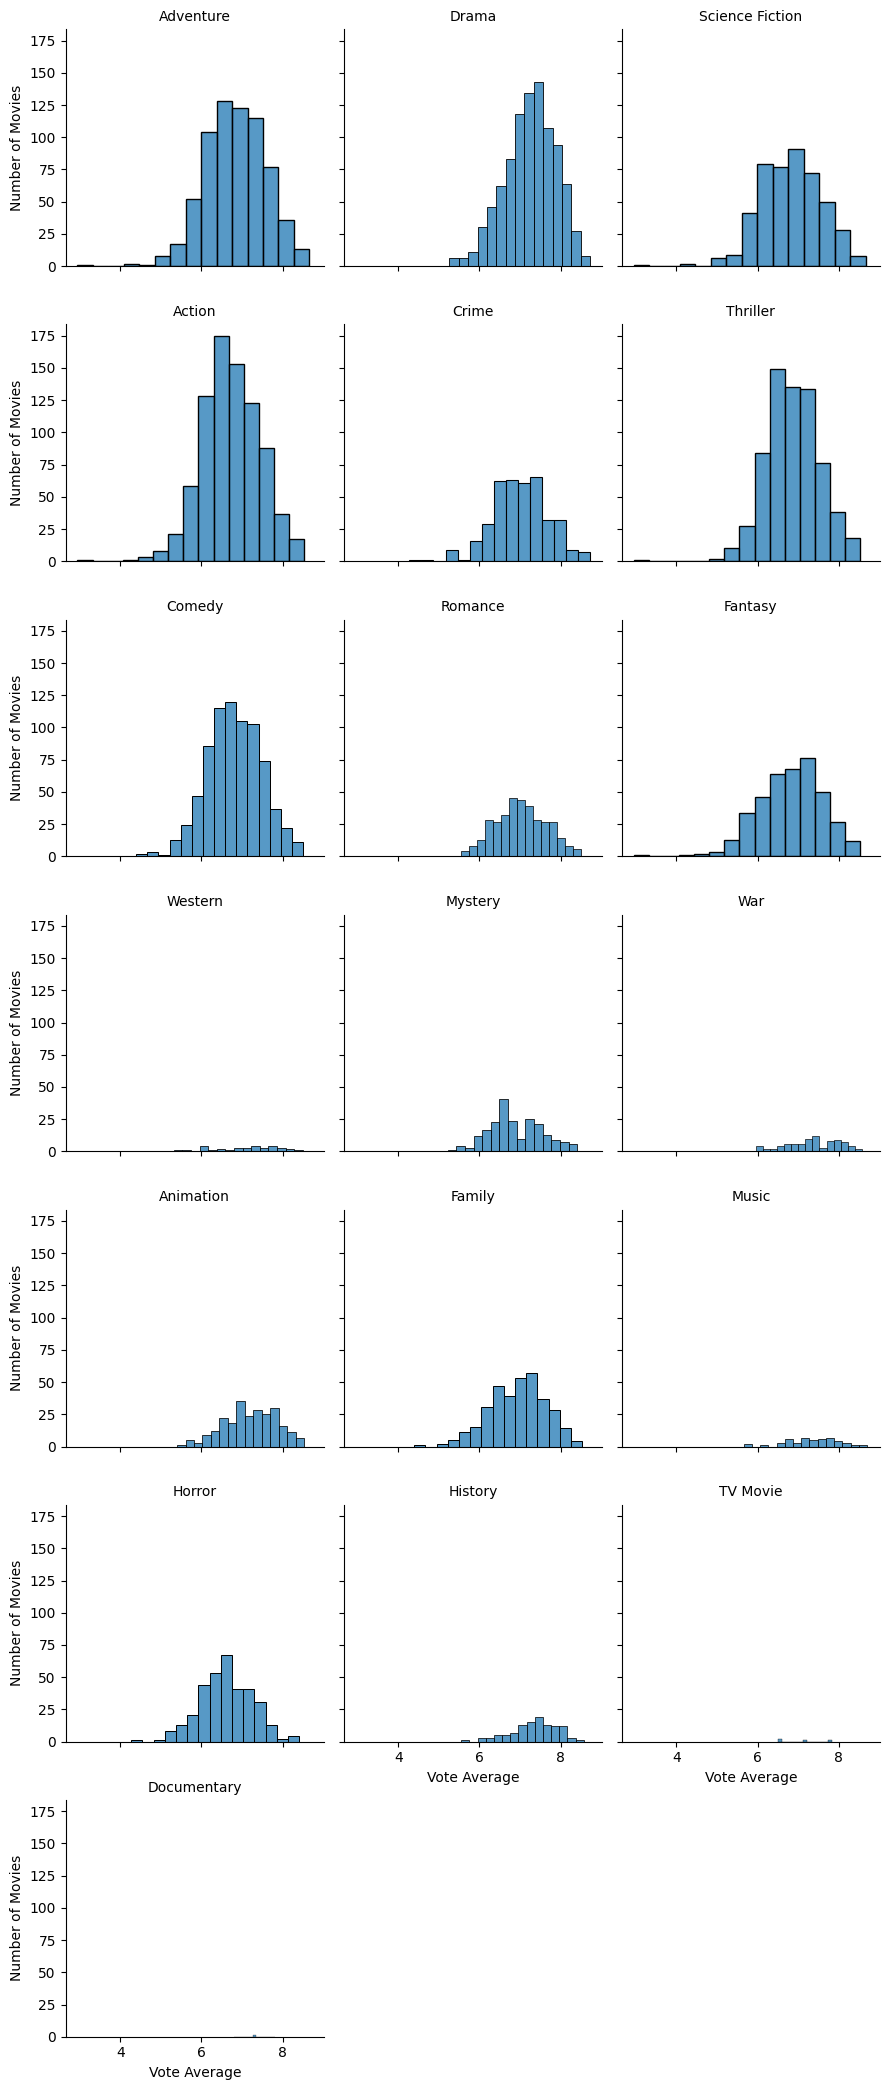

In [36]:
genre_data = movie_rating[
    ['vote_average', 'genre_name_x']
].dropna()

g = sns.FacetGrid(
    genre_data,
    col='genre_name_x',
    col_wrap=3,
    height=3
)

g.map_dataframe(
    sns.histplot,
    x='vote_average',
    bins=15
)

g.set_axis_labels('Vote Average', 'Number of Movies')
g.set_titles('{col_name}')

plt.show()

####Insight
Rating distributions vary across genres, showing that audience rating patterns are not identical for all movie categories.

###Average Revenue by Genre and Release Decade

In [42]:
movie_rating['release_year'] = pd.to_datetime(
    movie_rating['release_date'],
    errors='coerce'
).dt.year

In [43]:
movie_rating['release_decade'] = (
    movie_rating['release_year'] // 10
) * 10

In [44]:
revenue_data = movie_rating[
    (movie_rating['revenue'] > 0)
].dropna(
    subset=['genre_name_x', 'release_decade']
)

In [45]:
pivot_data = revenue_data.pivot_table(
    values='revenue',
    index='genre_name_x',
    columns='release_decade',
    aggfunc='mean'
)


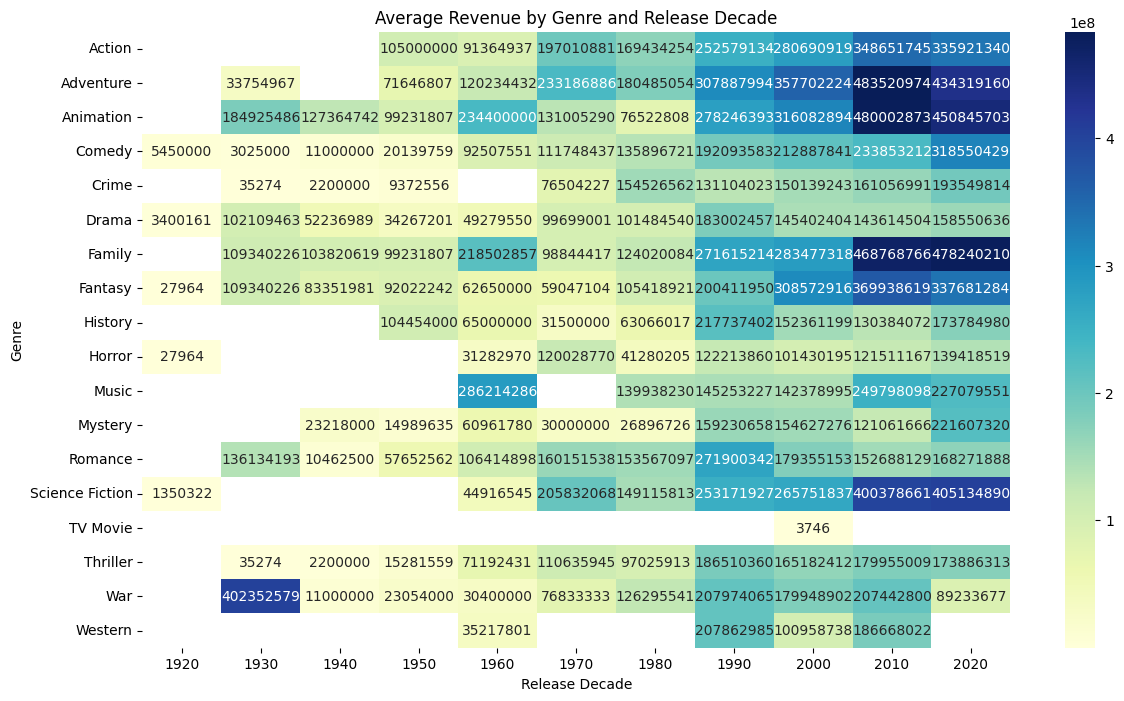

In [46]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    pivot_data,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)

plt.title('Average Revenue by Genre and Release Decade')
plt.xlabel('Release Decade')
plt.ylabel('Genre')

plt.show()

####Insight
The heatmap highlights changes in average movie revenue across genres and decades, helping identify which genres performed better during different periods.